# 02 · Keluarga GAN: Vanilla GAN & DCGAN
**Deep Learning (D6421) – Sesi 07: Generative Models | Tugas Take-Home**

Melatih Vanilla GAN (fully-connected) dan DCGAN (fully-convolutional), mencatat loss per iterasi, D(x), D(G(z)), dan gradient norm G, lalu menghitung FID, coverage, dan latency. Bahan untuk Q2, Q3, Q4, Q6.

**Sebelum run (Colab):** *Runtime → Change runtime type → T4 GPU*. Notebook akan meminta izin mount Google Drive; semua checkpoint, tabel, dan figur disimpan ke folder `GSLC2/final_results/` di Drive.

Notebook ini **mandiri**: model yang dibutuhkan tapi belum ada di Drive akan dilatih di sini. Kalau sudah dilatih notebook lain (folder output yang sama), checkpoint-nya langsung dimuat.

## 1. Setup

In [1]:
!pip install -q torch-fidelity torchmetrics

In [2]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import copy
import csv
import glob
import json
import math
import random
import shutil
import statistics
import time
from dataclasses import asdict, dataclass
from typing import Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, Markdown, display
from matplotlib.gridspec import GridSpec
from torch.utils.data import DataLoader, TensorDataset

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.14.1+cu130 | CUDA: True | Tesla T4


### Konfigurasi
Semua hyperparameter ada di sini, jadi bisa langsung dipindah ke **Tabel Konfigurasi** (Bagian II laporan). Nilainya identik di kelima notebook.

In [3]:
@dataclass
class Config:
    # ---- Umum ----
    seed: int = 42
    data_root: str = "./data"
    out_dir: str = "./outputs"
    batch_size: int = 128
    num_workers: int = 0              # data di-preload ke tensor -> 0 sudah cepat
    fake_data: bool = False           # True = smoke test dengan data sintetis
    deterministic: bool = False
    train_frac: float = 0.8
    val_frac: float = 0.1

    # ---- Keluarga Autoencoder (backbone sama: 784-256-64-256-784) ----
    img_dim: int = 784
    hidden_dim: int = 256
    latent_dim: int = 64
    ae_epochs: int = 30
    ae_lr: float = 1e-3
    sparse_lambda: float = 1e-4       # lambda * ||h||_1
    sparse_sweep: Tuple[float, ...] = (0.0, 1e-5, 1e-4, 1e-3)
    sweep_epochs: int = 20
    vae_recon_loss: str = "bce"       # "bce" | "mse" (dijumlah per citra)
    vae_beta: float = 1.0

    # ---- GAN ----
    z_dim: int = 100
    gan_epochs: int = 60
    dcgan_epochs: int = 30
    gan_lr: float = 2e-4
    gan_beta1: float = 0.5
    gan_loss: str = "nonsat"          # "nonsat" | "minimax"
    dcgan_ngf: int = 64
    dcgan_ndf: int = 64
    gan_log_every: int = 10

    # ---- DDPM ----
    ddpm_epochs: int = 40
    ddpm_lr: float = 2e-4
    ddpm_T: int = 1000
    ddpm_beta_start: float = 1e-4
    ddpm_beta_end: float = 0.02
    ddpm_base_ch: int = 64
    ddpm_ch_mults: Tuple[int, ...] = (1, 2, 2)
    ddpm_num_res_blocks: int = 2
    ddpm_attn_res: Tuple[int, ...] = (7,)
    ddpm_dropout: float = 0.1
    ddpm_ema_decay: float = 0.999
    ddpm_amp: bool = True
    ddpm_sample_batch: int = 500
    ddpm_val_batches: int = 20

    # ---- MLP Classifier (Bagian 2): 784 -> 256 -> 64 -> 10 ----
    clf_epochs: int = 25
    clf_lr: float = 1e-3
    clf_dropout: float = 0.2
    clf_min_acc: float = 0.88
    latent_dec_epochs: int = 30       # = ae_epochs agar adil vs Vanilla AE

    # ---- Evaluasi ----
    fid_feature: int = 2048
    fid_n_samples: int = 0            # 0 = samakan dengan ukuran test set
    fid_batch: int = 100              # Inception resize ke 299x299 -> batch besar = OOM di T4
    latency_batch: int = 64
    latency_runs: int = 20
    latency_runs_ddpm: int = 3
    interp_classes: Tuple[int, int] = (1, 8)      # Trouser vs Bag
    interp_alphas: Tuple[float, ...] = (0.0, 0.2, 0.4, 0.6, 0.8, 1.0)
    gan_interp_candidates: int = 2000

    def apply_fake_data_overrides(self):
        """Mode smoke test: semuanya kecil agar pipeline bisa dicek cepat di CPU."""
        self.ae_epochs = self.sweep_epochs = self.clf_epochs = self.latent_dec_epochs = 1
        self.gan_epochs = self.dcgan_epochs = self.ddpm_epochs = 1
        self.ddpm_T = 20
        self.ddpm_base_ch = 32
        self.ddpm_num_res_blocks = 1
        self.ddpm_sample_batch = 64
        self.ddpm_val_batches = 2
        self.fid_n_samples = 128
        self.latency_runs = 2
        self.latency_runs_ddpm = 1
        self.sparse_sweep = (0.0, 1e-4)
        self.clf_min_acc = 0.0
        self.gan_interp_candidates = 200


CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


GENERATIVE = ["vanilla_ae", "sparse_ae", "vae", "vanilla_gan", "dcgan", "ddpm"]


PRETTY = {"vanilla_ae": "Vanilla AE", "sparse_ae": "Sparse AE", "vae": "VAE",
          "vanilla_gan": "Vanilla GAN", "dcgan": "DCGAN", "ddpm": "DDPM",
          "mlp_classifier": "MLP Classifier", "latent_decoder": "Frozen-Latent Decoder"}

### Utilitas

In [4]:
def set_seed(seed=42, deterministic=False):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path


def _json_default(o):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, torch.Tensor):
        return o.detach().cpu().tolist()
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"Tidak bisa serialisasi {type(o)}")


def save_json(obj, path):
    ensure_dir(os.path.dirname(path) or ".")
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=_json_default)


def to_01(x):
    """[-1, 1] -> [0, 1]"""
    return ((x + 1) / 2).clamp(0, 1)


def to_pm1(x):
    """[0, 1] -> [-1, 1]"""
    return x * 2 - 1


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def _sync(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def measure_latency(fn, device, n_warmup=3, n_runs=20):
    """Median & std latensi (ms) satu pemanggilan fn(). synchronize agar waktu GPU terhitung."""
    for _ in range(n_warmup):
        fn()
    _sync(device)
    times = []
    for _ in range(n_runs):
        _sync(device)
        t0 = time.perf_counter()
        fn()
        _sync(device)
        times.append((time.perf_counter() - t0) * 1000.0)
    return {"median_ms": statistics.median(times),
            "std_ms": statistics.pstdev(times) if len(times) > 1 else 0.0,
            "n_runs": n_runs}


def _free_cuda():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

### Data
torchvision memberi split 60k/10k; keduanya digabung (70k) lalu dipecah ulang **80/10/10** dengan seed 42. Karena seed-nya sama, kelima notebook mendapat split yang identik.

In [5]:
def _load_fashion_mnist(root):
    from torchvision.datasets import FashionMNIST
    tr = FashionMNIST(root, train=True, download=True)
    te = FashionMNIST(root, train=False, download=True)
    # Gabung split resmi 60k + 10k = 70k, lalu split ulang 80/10/10.
    x = torch.cat([tr.data, te.data], 0).float().div_(255.0).unsqueeze(1)  # (70000,1,28,28) in [0,1]
    y = torch.cat([tr.targets, te.targets], 0).long()
    return x, y


def _make_fake_data(n=3000, seed=0):
    """Data sintetis (blob) HANYA untuk smoke test pipeline, bukan untuk laporan."""
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, 10, (n,), generator=g)
    yy, xx = torch.meshgrid(torch.arange(28.0), torch.arange(28.0), indexing="ij")
    cx = 6 + 1.6 * y.float() + torch.randn(n, generator=g)
    cy = 14 + 3 * torch.randn(n, generator=g)
    r = 4 + 0.3 * y.float()
    d = ((xx[None] - cx[:, None, None]) ** 2 + (yy[None] - cy[:, None, None]) ** 2).sqrt()
    return torch.sigmoid((r[:, None, None] - d) * 1.5).unsqueeze(1).clamp(0, 1), y


def get_data(cfg):
    x, y = _make_fake_data(seed=cfg.seed) if cfg.fake_data else _load_fashion_mnist(cfg.data_root)
    n = len(x)
    n_train, n_val = int(cfg.train_frac * n), int(cfg.val_frac * n)
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(cfg.seed))
    idx = {"train": perm[:n_train], "val": perm[n_train:n_train + n_val], "test": perm[n_train + n_val:]}
    torch.save(idx, os.path.join(cfg.out_dir, "logs", "split_indices.pt"))
    save_json({"n_total": n, **{f"n_{k}": len(v) for k, v in idx.items()}, "seed": cfg.seed},
              os.path.join(cfg.out_dir, "logs", "split_info.json"))
    ds = {k: TensorDataset(x[v], y[v]) for k, v in idx.items()}

    pin = torch.cuda.is_available()
    loaders = {
        "train": DataLoader(ds["train"], batch_size=cfg.batch_size, shuffle=True, drop_last=True,
                            num_workers=cfg.num_workers, pin_memory=pin,
                            generator=torch.Generator().manual_seed(cfg.seed)),
        "val": DataLoader(ds["val"], batch_size=cfg.batch_size, shuffle=False,
                          num_workers=cfg.num_workers, pin_memory=pin),
        "test": DataLoader(ds["test"], batch_size=cfg.batch_size, shuffle=False,
                           num_workers=cfg.num_workers, pin_memory=pin),
    }
    log(f"Data: total={n} | train={len(idx['train'])} val={len(idx['val'])} test={len(idx['test'])}")
    return ds, loaders

## 2. Pengaturan Run
- Run penuh untuk laporan. Semua hasil tersimpan langsung ke Drive: `GSLC2/final_results/`.
- Semua notebook Colab berbagi folder ini, jadi model yang sudah dilatih notebook lain langsung dimuat.

In [6]:
# ======================= PENGATURAN RUN =======================
FAKE_DATA = False     # smoke test dengan data sintetis (JANGAN untuk laporan)
SKIP_FID = False
RETRAIN = []          # mis. ["dcgan"] untuk paksa latih ulang walau checkpoint sudah ada di Drive

# Folder Google Drive (My Drive > Binus > Semester_5 > DeepLearning > GSLC2)
DRIVE_DIR = "/content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = DRIVE_DIR
    DATA_ROOT = "/content/data"           # dataset di disk lokal Colab (lebih cepat dari Drive)
except ImportError:                       # dijalankan di luar Colab
    BASE = "./GSLC2"
    DATA_ROOT = "./data"

cfg = Config(data_root=DATA_ROOT,
             out_dir=os.path.join(BASE, "final_results"))
if FAKE_DATA:
    cfg.fake_data = True
    cfg.apply_fake_data_overrides()

for d in ["checkpoints", "logs", "figures", "metrics", "samples"]:
    ensure_dir(os.path.join(cfg.out_dir, d))

# Tes tulis ke Drive: gagal di sini = Drive penuh / path salah -> berhenti sebelum training
_probe = os.path.join(cfg.out_dir, ".write_test")
try:
    with open(_probe, "wb") as f:
        f.write(os.urandom(1024 * 1024))
    os.remove(_probe)
except OSError as e:
    raise RuntimeError(f"Tidak bisa menulis ke {cfg.out_dir}. Cek storage Google Drive / path DRIVE_DIR. ({e})")

device = get_device()
set_seed(cfg.seed, cfg.deterministic)
print("Output dir:", os.path.abspath(cfg.out_dir))
print("Device    :", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Mounted at /content/drive
Output dir: /content/drive/MyDrive/Binus/Semester_5/DeepLearning/GSLC2/final_results
Device    : cuda Tesla T4


In [7]:
ds, loaders = get_data(cfg)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.73MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.2MB/s]


[13:17:07] Data: total=70000 | train=56000 val=7000 test=7000


In [8]:
def ckpt_path(name):
    return os.path.join(cfg.out_dir, "checkpoints", f"{name}.pt")


def load_or_train(name, train_fn):
    """Load checkpoint dari Drive kalau ada (dan tidak di RETRAIN); kalau tidak, latih lalu simpan."""
    path = ckpt_path(name)
    if os.path.exists(path) and name not in RETRAIN:
        ck = torch.load(path, map_location=device, weights_only=False)
        mods = build_models(name, cfg, device)
        for k, sd in ck["state"].items():
            mods[k].load_state_dict(sd)
        hist = ck["hist"]
        log(f"Checkpoint dimuat dari Drive: {name}")
    else:
        log(f"=== Training {PRETTY.get(name, name)} ===")
        # Reset urutan shuffle -> hasil tiap model tidak bergantung pada model lain yang dilatih sebelumnya
        loaders["train"].generator.manual_seed(cfg.seed)
        mods, hist = train_fn()
        torch.save({"state": {k: v.state_dict() for k, v in mods.items()}, "hist": hist,
                    "config": asdict(cfg)}, path)
        save_json(hist, os.path.join(cfg.out_dir, "logs", f"{name}_history.json"))
    for v in mods.values():
        v.eval()
    return mods, hist


def show_fig(name, width=1100):
    display(Image(filename=os.path.join(cfg.out_dir, "figures", name), width=width))

## 3. Model
$\mathcal{L}_D=-\mathbb{E}[\log D(x)]-\mathbb{E}[\log(1-D(G(z)))]$. Default $\mathcal{L}_G=-\mathbb{E}[\log D(G(z))]$ (non-saturating); set `cfg.gan_loss = "minimax"` untuk formulasi asli (eksperimen vanishing gradient — pakai folder output lain).

MLP Classifier dipakai untuk *class coverage* (proxy mode collapse) dan memilih titik ujung interpolasi.

In [9]:
class MLPGenerator(nn.Module):
    """Vanilla GAN G: z(100) -> 256 -> 512 -> 1024 -> 784, Tanh. Tanpa BatchNorm."""

    def __init__(self, z_dim=100, img_dim=784):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, img_dim), nn.Tanh())

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class MLPDiscriminator(nn.Module):
    """Vanilla GAN D: 784 -> 512 -> 256 -> 1 (logit)."""

    def __init__(self, img_dim=784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), nn.Linear(img_dim, 512), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256), nn.LeakyReLU(0.2, inplace=True), nn.Linear(256, 1))

    def forward(self, x):
        return self.net(x).view(-1)


class DCGANGenerator(nn.Module):
    """Pedoman Radford et al.: ConvTranspose berstride, BatchNorm, ReLU, Tanh output, tanpa FC hidden.
    z(100x1x1) -> 7x7 -> 14x14 -> 28x28"""

    def __init__(self, z_dim=100, ngf=64):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, ngf * 4, 7, 1, 0, bias=False), nn.BatchNorm2d(ngf * 4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf * 2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, 1, 4, 2, 1, bias=False), nn.Tanh())

    def forward(self, z):
        return self.net(z.view(z.size(0), self.z_dim, 1, 1))


class DCGANDiscriminator(nn.Module):
    """Conv berstride (tanpa pooling), BatchNorm (kecuali layer input), LeakyReLU. 28 -> 14 -> 7 -> 1"""

    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, 1, 7, 1, 0, bias=False))

    def forward(self, x):
        return self.net(x).view(-1)


def dcgan_weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


def d_loss_fn(d_real, d_fake):
    """L_D = -E[log D(x)] - E[log(1 - D(G(z)))]  (D mengeluarkan logit)."""
    return (F.binary_cross_entropy_with_logits(d_real, torch.ones_like(d_real))
            + F.binary_cross_entropy_with_logits(d_fake, torch.zeros_like(d_fake)))


def g_loss_fn(d_fake, kind="nonsat"):
    """nonsat : L_G = -E[log D(G(z))]       (heuristik Goodfellow 2014, gradien kuat di awal)
       minimax: L_G =  E[log(1 - D(G(z)))]  (formulasi asli, gradien hilang saat D yakin)"""
    if kind == "minimax":
        return -F.binary_cross_entropy_with_logits(d_fake, torch.zeros_like(d_fake))
    return F.binary_cross_entropy_with_logits(d_fake, torch.ones_like(d_fake))

In [10]:
class MLPClassifier(nn.Module):
    """784 -> 256 -> 64 -> 10. Bobot PyTorch berbentuk (out, in):
    W1=(256,784), W2=(64,256), W3=(10,64). z_MLP = ReLU(W2 ReLU(W1 x + b1) + b2) in R^64."""

    def __init__(self, img_dim=784, h1=256, h2=64, n_classes=10, dropout=0.2):
        super().__init__()
        self.fc1, self.fc2, self.fc3 = nn.Linear(img_dim, h1), nn.Linear(h1, h2), nn.Linear(h2, n_classes)
        self.drop = nn.Dropout(dropout)

    def features(self, x):
        return torch.relu(self.fc2(self.drop(torch.relu(self.fc1(x.flatten(1))))))

    def forward(self, x):
        return self.fc3(self.drop(self.features(x)))

    def weights(self):
        return self.fc1.weight.detach(), self.fc2.weight.detach(), self.fc3.weight.detach()


def train_classifier(cfg, loaders, device):
    """Tahap 1: MLP Classifier 784-256-64-10 dengan Cross-Entropy."""
    set_seed(cfg.seed, cfg.deterministic)
    clf = build_models("mlp_classifier", cfg, device)["model"]
    opt = torch.optim.Adam(clf.parameters(), lr=cfg.clf_lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best, best_state = -1.0, None
    for ep in range(1, cfg.clf_epochs + 1):
        clf.train()
        t0 = time.perf_counter()
        tot, n = 0.0, 0
        for x, y in loaders["train"]:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(clf(x), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.item()
            n += 1
        hist["epoch_time"].append(time.perf_counter() - t0)
        hist["train_loss"].append(tot / n)
        vl, va = evaluate_classifier(clf, loaders["val"], device)
        hist["val_loss"].append(vl)
        hist["val_acc"].append(va)
        if va > best:
            best, best_state = va, copy.deepcopy(clf.state_dict())
        log(f"MLP Classifier ep {ep}/{cfg.clf_epochs} | train {tot / n:.4f} | val loss {vl:.4f} acc {va:.4f}")
    clf.load_state_dict(best_state)
    return {"model": clf}, hist


@torch.no_grad()
def evaluate_classifier(clf, loader, device):
    clf.eval()
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = clf(x)
        tot += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return tot / n, correct / n

In [11]:
def build_models(name, cfg, device):
    if name == "vanilla_gan":
        m = {"G": MLPGenerator(cfg.z_dim, cfg.img_dim), "D": MLPDiscriminator(cfg.img_dim)}
    elif name == "dcgan":
        m = {"G": DCGANGenerator(cfg.z_dim, cfg.dcgan_ngf), "D": DCGANDiscriminator(cfg.dcgan_ndf)}
        m["G"].apply(dcgan_weights_init)
        m["D"].apply(dcgan_weights_init)
    elif name == "mlp_classifier":
        m = {"model": MLPClassifier(cfg.img_dim, 256, 64, 10, cfg.clf_dropout)}
    else:
        raise ValueError(name)
    return {k: v.to(device) for k, v in m.items()}

## 4. Training Loop

In [12]:
def _grad_norm(module):
    total = 0.0
    for p in module.parameters():
        if p.grad is not None:
            total += p.grad.detach().pow(2).sum().item()
    return math.sqrt(total)


def train_gan(kind, cfg, loaders, device):
    set_seed(cfg.seed, cfg.deterministic)
    m = build_models(kind, cfg, device)
    G, D = m["G"], m["D"]
    epochs = cfg.gan_epochs if kind == "vanilla_gan" else cfg.dcgan_epochs
    opt_g = torch.optim.Adam(G.parameters(), lr=cfg.gan_lr, betas=(cfg.gan_beta1, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=cfg.gan_lr, betas=(cfg.gan_beta1, 0.999))
    fixed_z = torch.randn(64, cfg.z_dim, device=device,
                          generator=torch.Generator(device=device).manual_seed(cfg.seed))
    prog_dir = ensure_dir(os.path.join(cfg.out_dir, "figures", "progress"))
    snap_epochs = sorted({1, max(1, epochs // 4), max(1, epochs // 2), epochs})
    hist = {k: [] for k in ["g_loss", "d_loss", "d_x", "d_gz", "g_grad_norm", "epoch_time",
                            "iter_g_loss", "iter_d_loss"]}
    it = 0
    for ep in range(1, epochs + 1):
        G.train()
        D.train()
        _sync(device)
        t0 = time.perf_counter()
        s = np.zeros(5)
        n = 0
        for x, _ in loaders["train"]:
            x = to_pm1(x.to(device, non_blocking=True))
            z = torch.randn(x.size(0), cfg.z_dim, device=device)
            fake = G(z)
            # --- update D: maksimalkan log D(x) + log(1 - D(G(z))) ---
            d_real, d_fake = D(x), D(fake.detach())
            loss_d = d_loss_fn(d_real, d_fake)
            opt_d.zero_grad(set_to_none=True)
            loss_d.backward()
            opt_d.step()
            # --- update G ---
            d_fake_g = D(fake)
            loss_g = g_loss_fn(d_fake_g, cfg.gan_loss)
            opt_g.zero_grad(set_to_none=True)
            loss_g.backward()
            gn = _grad_norm(G)
            opt_g.step()

            s += [loss_g.item(), loss_d.item(), torch.sigmoid(d_real).mean().item(),
                  torch.sigmoid(d_fake).mean().item(), gn]
            n += 1
            if it % cfg.gan_log_every == 0:
                hist["iter_g_loss"].append(loss_g.item())
                hist["iter_d_loss"].append(loss_d.item())
            it += 1
        _sync(device)
        hist["epoch_time"].append(time.perf_counter() - t0)
        for k, v in zip(["g_loss", "d_loss", "d_x", "d_gz", "g_grad_norm"], s / n):
            hist[k].append(float(v))
        if ep in snap_epochs:
            G.eval()
            with torch.no_grad():
                _save_grid(to_01(G(fixed_z)), os.path.join(prog_dir, f"{kind}_epoch{ep:03d}.png"), nrow=8)
        log(f"{PRETTY[kind]} ep {ep}/{epochs} | L_G {hist['g_loss'][-1]:.4f} L_D {hist['d_loss'][-1]:.4f} "
            f"| D(x) {hist['d_x'][-1]:.3f} D(G(z)) {hist['d_gz'][-1]:.3f} | |grad G| {hist['g_grad_norm'][-1]:.3f} "
            f"| {hist['epoch_time'][-1]:.1f}s")
    hist["log_every"] = cfg.gan_log_every
    return {"G": G, "D": D}, hist

## 5. Metrik & Visualisasi

In [13]:
class FIDEvaluator:
    """FID memakai InceptionV3 (torchmetrics + torch-fidelity).

    Catatan: Fashion-MNIST grayscale 28x28 -> channel diulang 3x dan Inception
    meresize ke 299x299 secara internal. Nilai FID ini hanya sahih untuk
    perbandingan ANTARMODEL di setup yang sama, bukan dibandingkan dgn angka paper.
    """

    def __init__(self, real_loader, device, feature=2048, batch=100):
        from torchmetrics.image.fid import FrechetInceptionDistance
        self.device, self.batch = device, batch
        _free_cuda()
        self.fid = FrechetInceptionDistance(feature=feature, normalize=True,
                                            reset_real_features=False).to(device)
        self.n_real = 0
        with torch.no_grad():
            for x, _ in real_loader:
                for i in range(0, len(x), batch):
                    xb = x[i:i + batch].to(device)
                    self.fid.update(xb.repeat(1, 3, 1, 1), real=True)
                    self.n_real += len(xb)
        log(f"FID: statistik real dihitung dari {self.n_real} citra test")

    @torch.no_grad()
    def score(self, samples01):
        """samples01: tensor CPU [0,1] (N,1,28,28). Diumpankan ke Inception per batch kecil."""
        _free_cuda()
        self.fid.reset()          # hanya fitur fake yang di-reset (reset_real_features=False)
        for i in range(0, len(samples01), self.batch):
            xb = samples01[i:i + self.batch].to(self.device).clamp(0, 1)
            self.fid.update(xb.repeat(1, 3, 1, 1), real=False)
        return self.fid.compute().item()


@torch.no_grad()
def class_coverage(clf, imgs01, device, batch=500):
    """Proxy mode coverage: distribusi kelas sampel menurut MLP Classifier.
    Entropi ternormalisasi 1.0 = merata di 10 kelas; rendah = indikasi mode collapse.
    Caveat: classifier ~88-90% akurat, jadi ini indikator kasar."""
    clf.eval()
    preds = torch.cat([clf(imgs01[i:i + batch].to(device)).argmax(1).cpu()
                       for i in range(0, len(imgs01), batch)])
    p = torch.bincount(preds, minlength=10).float() / len(preds)
    ent = abs(-(p[p > 0] * p[p > 0].log()).sum().item() / math.log(10))
    return {"class_hist": p.tolist(), "class_entropy_norm": ent,
            "n_classes_over_2pct": int((p > 0.02).sum().item())}


def loss_stability(values, last_frac=0.25):
    """Koefisien variasi (std/|mean|) loss di 25% akhir training -> proxy osilasi."""
    v = np.asarray(values, dtype=float)
    if len(v) < 2:
        return float("nan")
    tail = v[-max(2, int(len(v) * last_frac)):]
    return float(tail.std() / (abs(tail.mean()) + 1e-12))

In [14]:
@torch.no_grad()
def run_interpolation(models, clf, ds, loaders, cfg, device):
    cA, cB = cfg.interp_classes
    X, Y = ds["test"].tensors
    xa = X[(Y == cA).nonzero()[0, 0]][None].to(device)
    xb = X[(Y == cB).nonzero()[0, 0]][None].to(device)
    alphas = torch.tensor(cfg.interp_alphas, device=device)[:, None]
    rows, stats = {}, {}

    for name in ["vanilla_ae", "sparse_ae", "vae"]:
        if name not in models:
            continue
        m = models[name]["model"].eval()
        enc = (lambda x, m=m: m.encode(x)[0]) if name == "vae" else m.encode
        za, zb = enc(xa), enc(xb)
        zp = (1 - alphas) * za + alphas * zb
        rows[name] = m.decode(zp).cpu()
        Zref, _ = collect_latents(enc, loaders["test"], device)
        stats[name] = {"nn_dist_ratio": nn_distance_ratio(zp.cpu(), Zref)}

    clf.eval()
    for name in ["vanilla_gan", "dcgan"]:
        if name not in models:
            continue
        G = models[name]["G"].eval()
        g = torch.Generator(device=device).manual_seed(cfg.seed)
        zc = torch.randn(cfg.gan_interp_candidates, cfg.z_dim, device=device, generator=g)
        probs = torch.cat([torch.softmax(clf(to_01(G(zc[i:i + 500]))), 1)
                           for i in range(0, len(zc), 500)])
        ia, ib = probs[:, cA].argmax(), probs[:, cB].argmax()
        zp = (1 - alphas) * zc[ia] + alphas * zc[ib]
        rows[name] = to_01(G(zp)).cpu()
        stats[name] = {"endpoint_conf": [probs[ia, cA].item(), probs[ib, cB].item()]}

    for name, r in rows.items():
        diffs = (r[1:] - r[:-1]).pow(2).flatten(1).mean(1)
        stats[name]["consecutive_mse"] = diffs.tolist()
        stats[name]["max_over_mean_jump"] = (diffs.max() / diffs.mean().clamp_min(1e-12)).item()
    return rows, stats

In [15]:
def _save_grid(imgs, path, nrow=8):
    from torchvision.utils import save_image
    save_image(imgs.cpu(), path, nrow=nrow, padding=2, pad_value=1.0)


def _grid_np(imgs, nrow, pad_value=1.0):
    from torchvision.utils import make_grid
    return make_grid(imgs.cpu(), nrow=nrow, padding=2, pad_value=pad_value)[0].numpy()


def _savefig(fig, cfg, name):
    path = os.path.join(cfg.out_dir, "figures", name)
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.close(fig)
    log(f"Figur disimpan: {path}")
    return path


def _image_rows(rows, row_labels, col_labels, title, figsize_per=(1.1, 1.15)):
    n_rows, n_cols = len(rows), rows[0].shape[0]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_per[0] + 1.5, n_rows * figsize_per[1]),
                             squeeze=False)
    for i, (r, lab) in enumerate(zip(rows, row_labels)):
        for j in range(n_cols):
            ax = axes[i, j]
            ax.imshow(r[j, 0].numpy(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=9)
            if i == 0 and col_labels is not None:
                ax.set_title(col_labels[j], fontsize=8)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    return fig

In [16]:
def _fmt(d):
    return {"MSE": round(d["mse"], 5), "PSNR (dB)": round(d["psnr"], 2), "SSIM": round(d["ssim"], 4)}


def _write_table(rows, path_no_ext):
    if not rows:
        return
    keys = list(rows[0].keys())
    with open(path_no_ext + ".csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys)
        w.writeheader()
        w.writerows(rows)
    flat = lambda v: f"{v:.4g}" if isinstance(v, float) else str(v)
    md = ["| " + " | ".join(keys) + " |", "|" + "---|" * len(keys)]
    md += ["| " + " | ".join(flat(r[k]) for k in keys) + " |" for r in rows]
    with open(path_no_ext + ".md", "w") as f:
        f.write("\n".join(md) + "\n")
    print("\n".join(md), flush=True)

In [17]:
def make_fid():
    if SKIP_FID:
        return None
    try:
        return FIDEvaluator(loaders["test"], device, cfg.fid_feature, cfg.fid_batch)
    except Exception as e:     # mis. tanpa internet untuk bobot Inception
        log(f"FID dilewati: {e!r}")
        return None


def make_sampler(name, mods):
    """b -> citra [0,1], dengan generator ber-seed tetap (sama seperti versi satu file)."""
    g = torch.Generator(device=device).manual_seed(cfg.seed + 1)
    if name == "vae":
        return lambda b: mods["model"].sample(b, device, generator=g)
    if name in ("vanilla_gan", "dcgan"):
        return lambda b: to_01(mods["G"](torch.randn(b, cfg.z_dim, device=device, generator=g)))
    if name == "ddpm":
        return lambda b: to_01(mods["diffusion"].sample(mods["ema"], b, device, generator=g, amp=cfg.ddpm_amp)[0])
    raise ValueError(name)


@torch.no_grad()
def generate(name, mods, n):
    batch = cfg.ddpm_sample_batch if name == "ddpm" else 1000
    fn, out, done = make_sampler(name, mods), [], 0
    while done < n:
        b = min(batch, n - done)
        out.append(fn(b).cpu())
        done += b
    return torch.cat(out)


def evaluate_generation(name, mods, clf, fid_eval):
    """Latency generate (batch 64), sampel untuk FID & coverage, simpan 256 sampel ke Drive."""
    _free_cuda()
    r = {}
    fn = make_sampler(name, mods)
    runs = cfg.latency_runs_ddpm if name == "ddpm" else cfg.latency_runs
    warm = 1 if name == "ddpm" else 3
    r["latency_generate"] = measure_latency(lambda: fn(cfg.latency_batch), device, warm, runs)
    n_fid = cfg.fid_n_samples or len(ds["test"])
    log(f"Generate {n_fid} sampel {PRETTY[name]} untuk FID/coverage ...")
    t0 = time.perf_counter()
    samples = generate(name, mods, n_fid)
    r["generate_time_total_s"] = time.perf_counter() - t0
    r["fid_n_samples"] = n_fid
    torch.save(samples[:256], os.path.join(cfg.out_dir, "samples", f"{name}.pt"))
    r["coverage"] = class_coverage(clf, samples, device)
    if fid_eval is not None:
        r["fid"] = fid_eval.score(samples)
    return r

## 6. Training

In [18]:
clf_mods, clf_hist = load_or_train("mlp_classifier", lambda: train_classifier(cfg, loaders, device))
clf = clf_mods["model"]
_, test_acc = evaluate_classifier(clf, loaders["test"], device)
print(f"Test accuracy MLP Classifier: {test_acc:.4f}  (syarat >= {cfg.clf_min_acc})")

[13:17:09] Checkpoint dimuat dari Drive: mlp_classifier
Test accuracy MLP Classifier: 0.8959  (syarat >= 0.88)


In [19]:
models, hists = {}, {}
for name in ["vanilla_gan", "dcgan"]:
    models[name], hists[name] = load_or_train(name, lambda name=name: train_gan(name, cfg, loaders, device))

[13:17:09] === Training Vanilla GAN ===
[13:17:14] Vanilla GAN ep 1/60 | L_G 1.1390 L_D 0.9525 | D(x) 0.795 D(G(z)) 0.471 | |grad G| 1.484 | 4.0s
[13:17:17] Vanilla GAN ep 2/60 | L_G 1.7299 L_D 0.9695 | D(x) 0.686 D(G(z)) 0.384 | |grad G| 3.203 | 3.2s
[13:17:20] Vanilla GAN ep 3/60 | L_G 1.8281 L_D 0.9723 | D(x) 0.679 D(G(z)) 0.353 | |grad G| 3.724 | 3.2s
[13:17:23] Vanilla GAN ep 4/60 | L_G 1.6194 L_D 1.0498 | D(x) 0.645 D(G(z)) 0.371 | |grad G| 3.469 | 2.9s
[13:17:27] Vanilla GAN ep 5/60 | L_G 1.4408 L_D 1.0912 | D(x) 0.625 D(G(z)) 0.387 | |grad G| 3.061 | 3.5s
[13:17:30] Vanilla GAN ep 6/60 | L_G 1.3006 L_D 1.1367 | D(x) 0.606 D(G(z)) 0.401 | |grad G| 2.681 | 3.0s
[13:17:33] Vanilla GAN ep 7/60 | L_G 1.2606 L_D 1.1582 | D(x) 0.600 D(G(z)) 0.409 | |grad G| 2.501 | 2.9s
[13:17:36] Vanilla GAN ep 8/60 | L_G 1.1597 L_D 1.1951 | D(x) 0.583 D(G(z)) 0.423 | |grad G| 2.217 | 2.9s
[13:17:39] Vanilla GAN ep 9/60 | L_G 1.1736 L_D 1.1962 | D(x) 0.583 D(G(z)) 0.422 | |grad G| 2.154 | 3.2s
[13:17

### Progress sampel dari `fixed_z`
Berguna untuk melihat mode collapse secara visual sepanjang training.

dcgan_epoch001.png


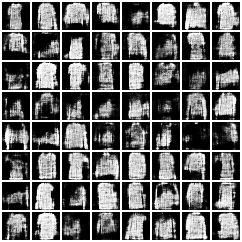

dcgan_epoch007.png


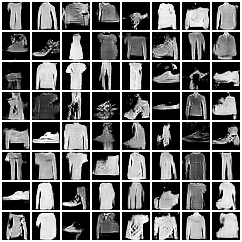

dcgan_epoch015.png


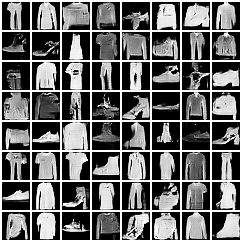

dcgan_epoch030.png


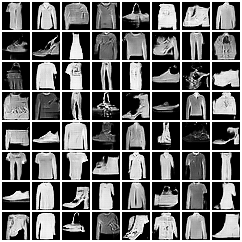

vanilla_gan_epoch001.png


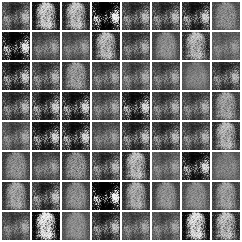

vanilla_gan_epoch015.png


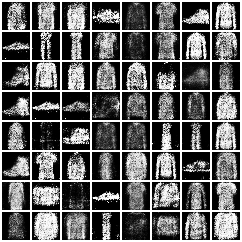

vanilla_gan_epoch030.png


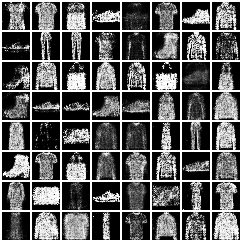

vanilla_gan_epoch060.png


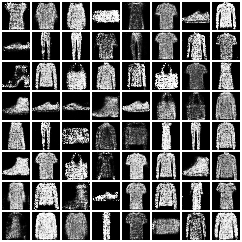

In [20]:
for f in sorted(glob.glob(os.path.join(cfg.out_dir, "figures", "progress", "*.png"))):
    print(os.path.basename(f))
    display(Image(filename=f, width=320))

## 7. Evaluasi

In [21]:
fid_eval = make_fid()
results = {}
for name in ["vanilla_gan", "dcgan"]:
    m, h = models[name], hists[name]
    r = {"model": PRETTY[name], "train_time_per_epoch_s": float(np.mean(h["epoch_time"])),
         "params": count_params(m["G"]), "latent_dim": f"{cfg.z_dim} (prior noise)"}
    r.update(evaluate_generation(name, m, clf, fid_eval))
    r["loss_cv_tail"] = loss_stability(h["g_loss"])
    r["d_loss_cv_tail"] = loss_stability(h["d_loss"])
    r["final_D(x)"], r["final_D(G(z))"] = h["d_x"][-1], h["d_gz"][-1]
    results[name] = r
    save_json(r, os.path.join(cfg.out_dir, "metrics", f"{name}.json"))

_write_table([{"Model": r["model"], "FID": round(r["fid"], 2) if "fid" in r else "N/A",
               "Class entropy": round(r["coverage"]["class_entropy_norm"], 3),
               "Kelas > 2%": r["coverage"]["n_classes_over_2pct"],
               "Latency gen (ms)": round(r["latency_generate"]["median_ms"], 3),
               "D(x) akhir": round(r["final_D(x)"], 3), "D(G(z)) akhir": round(r["final_D(G(z))"], 3)}
              for r in results.values()],
             os.path.join(cfg.out_dir, "metrics", "gans_table"))
for n, r in results.items():
    print(PRETTY[n], "distribusi kelas:", [round(p, 3) for p in r["coverage"]["class_hist"]])

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 319MB/s]


[13:28:29] FID: statistik real dihitung dari 7000 citra test
[13:28:29] Generate 7000 sampel Vanilla GAN untuk FID/coverage ...
[13:29:07] Generate 7000 sampel DCGAN untuk FID/coverage ...
| Model | FID | Class entropy | Kelas > 2% | Latency gen (ms) | D(x) akhir | D(G(z)) akhir |
|---|---|---|---|---|---|---|
| Vanilla GAN | 120.3 | 0.99 | 10 | 0.555 | 0.535 | 0.465 |
| DCGAN | 20.71 | 0.995 | 10 | 3.708 | 0.585 | 0.415 |
Vanilla GAN distribusi kelas: [0.112, 0.089, 0.126, 0.143, 0.086, 0.085, 0.109, 0.09, 0.093, 0.067]
DCGAN distribusi kelas: [0.092, 0.104, 0.083, 0.122, 0.1, 0.115, 0.121, 0.085, 0.095, 0.082]


### Interpolasi laten (bagian GAN untuk Figur 4)
GAN tidak punya encoder, jadi $z_A, z_B$ dipilih dari kandidat acak yang paling yakin diklasifikasikan ke kelas A/B.

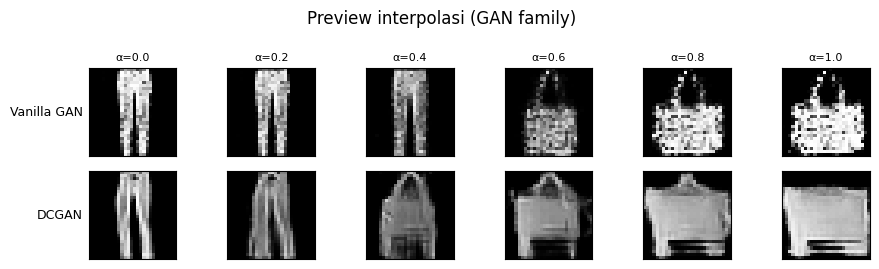

Vanilla GAN  confidence ujung = [1.0, 1.0] | max/mean jump = 2.26
DCGAN        confidence ujung = [1.0, 1.0] | max/mean jump = 1.50


In [22]:
interp_rows, interp_stats = run_interpolation(models, clf, ds, loaders, cfg, device)
torch.save(interp_rows, os.path.join(cfg.out_dir, "samples", "interp_rows_gan.pt"))
save_json(interp_stats, os.path.join(cfg.out_dir, "metrics", "interp_gan.json"))
fig = _image_rows([interp_rows[n] for n in interp_rows], [PRETTY[n] for n in interp_rows],
                  [f"α={a:.1f}" for a in cfg.interp_alphas], "Preview interpolasi (GAN family)", (1.3, 1.35))
plt.show()
for n, d in interp_stats.items():
    print(f"{PRETTY[n]:12s} confidence ujung = {[round(v, 3) for v in d['endpoint_conf']]}"
          f" | max/mean jump = {d['max_over_mean_jump']:.2f}")